# Sales & Profit Intelligence

**Portfolio case study · Synthetic data · Python / Pandas / Matplotlib**

This notebook calculates sales and profit metrics, checks data quality, compares product/category/region performance, and visualizes monthly trends. The dataset is synthetic and does not describe a real company. Calculated profit excludes operating expenses, taxes, and other business costs; it is not net profit.

Run from this notebook's folder. The shared metrics module resolves the CSV path relative to the project, independent of the kernel's working directory.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

current_directory = Path.cwd()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (current_directory, *current_directory.parents)
        if (candidate / "src" / "sales_profit_metrics.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate src/sales_profit_metrics.py from the current directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.sales_profit_metrics import (  # noqa: E402
    aggregate_metrics,
    format_percent,
    load_sales_data,
    summarize_metrics,
)

df = load_sales_data()
df.head()

,order_date,product,category,region,units_sold,unit_price,unit_cost,discount_rate,gross_sales,revenue_after_discounts,recorded_product_cost,calculated_profit,profit_margin,month
0,2025-01-08,Wireless Mouse,Accessories,North,18,24.99,10.5,0.05,449.82,427.3290,189.0,238.3290,0.5577178239716939407341884122,2025-01
1,2025-01-19,USB-C Hub,Accessories,West,12,39.99,19,0,479.88,479.88,228,251.88,0.5248812203050762690672668167,2025-01
2,2025-01-23,Office Chair,Furniture,East,5,149,92,0.1,745,670.5,460,210.5,0.3139448173005219985085756898,2025-01
3,2025-02-03,Notebook Pack,Stationery,South,35,8.5,3.1,0,297.5,297.5,108.5,189.0,0.6352941176470588235294117647,2025-02
4,2025-02-14,Desk Lamp,Furniture,North,9,32,15.5,0.05,288,273.60,139.5,134.10,0.4901315789473684210526315789,2025-02


## 2. Initial data-quality checks

Check shape, column types, missing values, duplicate rows, and invalid numeric values before calculating metrics.

In [2]:
print(f'Rows: {len(df):,} | Columns: {len(df.columns)}')
display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().to_frame('missing_values'))
print('Duplicate rows:', int(df.duplicated().sum()))

required_numeric = ['units_sold', 'unit_price', 'unit_cost', 'discount_rate']
invalid = (df[required_numeric].lt(0).any(axis=1) | df['discount_rate'].gt(1))
print('Rows with invalid numeric values:', int(invalid.sum()))
assert not df['order_date'].isna().any(), 'Missing order dates found'
assert not invalid.any(), 'Invalid numeric values found; investigate before analysis'

Rows: 49 | Columns: 14


,dtype
order_date,datetime64[us]
product,str
category,str
region,str
units_sold,object
unit_price,object
unit_cost,object
discount_rate,object
gross_sales,object
revenue_after_discounts,object


,missing_values
order_date,0
product,0
category,0
region,0
units_sold,0
unit_price,0
unit_cost,0
discount_rate,0
gross_sales,0
revenue_after_discounts,0


Duplicate rows: 0
Rows with invalid numeric values: 0


Revenue after discounts is gross sales multiplied by one minus the discount rate. Calculated profit is revenue after discounts less recorded product cost; it is not net profit. Monetary calculations retain decimal precision through aggregation, then round reported amounts to two decimals using ROUND_HALF_UP. Margins use unrounded aggregated totals and are formatted to one decimal percentage point.

In [3]:
overall = summarize_metrics(df)
summary = pd.DataFrame({
    "metric": [
        "Orders/rows",
        "Units sold",
        "Revenue after discounts",
        "Recorded product cost",
        "Calculated profit",
        "Profit margin",
    ],
    "value": [
        overall["record_count"],
        overall["units_sold"],
        overall["revenue_after_discounts"],
        overall["recorded_product_cost"],
        overall["calculated_profit"],
        format_percent(overall["profit_margin"]),
    ],
})
display(summary)

,metric,value
0,Orders/rows,49
1,Units sold,890
2,Revenue after discounts,39074.47
3,Recorded product cost,22642.90
4,Calculated profit,16431.57
5,Profit margin,42.1%


## 4. Product, category, and region performance

In [4]:
def performance_table(group_col):
    result = aggregate_metrics(df, group_col).set_index(group_col)
    result = result.rename(
        columns={
            "record_count": "records",
            "units_sold": "units",
            "revenue_after_discounts": "revenue",
            "recorded_product_cost": "cost",
            "calculated_profit": "profit",
        }
    )
    result["profit_margin"] = result["profit_margin"].map(format_percent)
    return result

display(performance_table("product"))
display(performance_table("category"))
display(performance_table("region"))

,records,units,revenue,cost,profit,profit_margin
product,,,,,,
Monitor 24in,7,69,11858.75,8349.00,3509.75,29.6%
USB-C Hub,8,135,5242.69,2565.00,2677.69,51.1%
Office Chair,7,51,7278.65,4692.00,2586.65,35.5%
Wireless Mouse,7,180,4358.26,1890.00,2468.26,56.6%
Mechanical Keyboard,6,68,5112.88,2856.00,2256.88,44.1%
Notebook Pack,7,299,2504.53,926.90,1577.63,63.0%
Desk Lamp,7,88,2718.72,1364.00,1354.72,49.8%


,records,units,revenue,cost,profit,profit_margin
category,,,,,,
Accessories,21,383,14713.83,7311.00,7402.83,50.3%
Furniture,14,139,9997.37,6056.00,3941.37,39.4%
Electronics,7,69,11858.75,8349.00,3509.75,29.6%
Stationery,7,299,2504.53,926.90,1577.63,63.0%


,records,units,revenue,cost,profit,profit_margin
region,,,,,,
North,13,240,10909.36,6348.80,4560.56,41.8%
South,12,237,9837.13,5572.50,4264.63,43.4%
East,13,201,10050.64,6053.50,3997.14,39.8%
West,11,212,8277.34,4668.10,3609.24,43.6%


## 5. Visualize the results

These charts use calculated values from the dataset. Labels and chart titles state what is being measured.

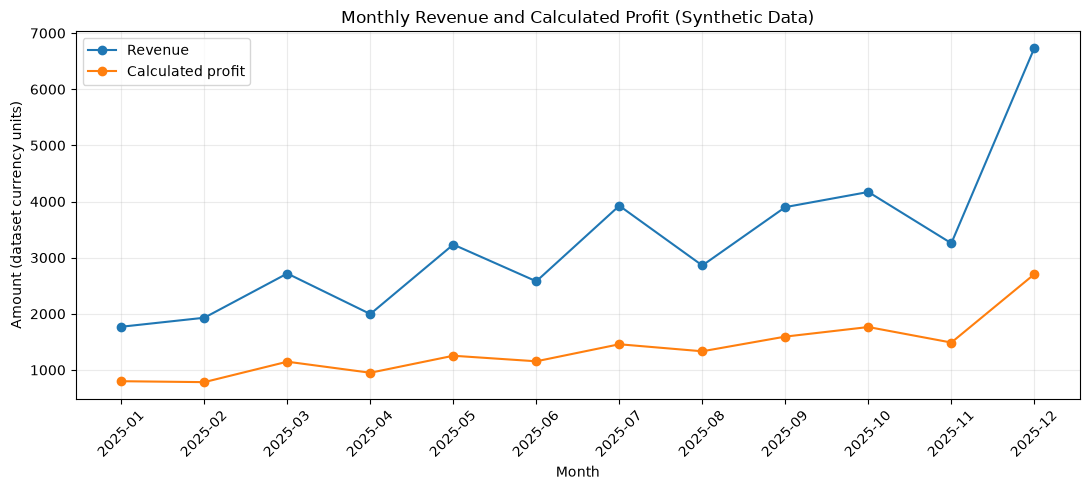

In [5]:
monthly = aggregate_metrics(df, "month").sort_values("month")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["month"], monthly["revenue_after_discounts"].map(float), marker="o", label="Revenue")
ax.plot(monthly["month"], monthly["calculated_profit"].map(float), marker="o", label="Calculated profit")
ax.set_title("Monthly Revenue and Calculated Profit (Synthetic Data)")
ax.set_xlabel("Month")
ax.set_ylabel("Amount (dataset currency units)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

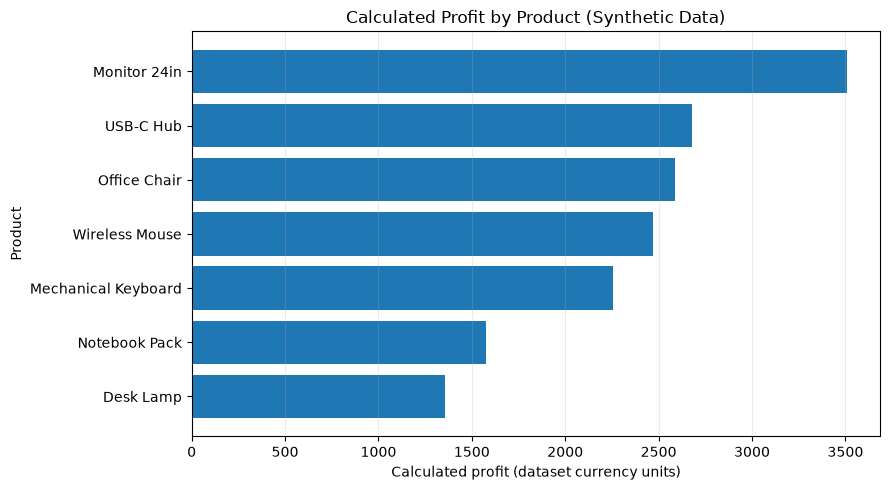

In [6]:
by_product = performance_table("product").sort_values("profit", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(by_product.index, by_product["profit"].map(float))
ax.set_title("Calculated Profit by Product (Synthetic Data)")
ax.set_xlabel("Calculated profit (dataset currency units)")
ax.set_ylabel("Product")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Findings to investigate

The following cell prints the strongest observed groups. Treat these as findings from a synthetic demonstration dataset only, not as claims about a real business. Review the tables and charts before writing recommendations.

In [7]:
category_results = performance_table("category")
region_results = performance_table("region")
product_results = performance_table("product")
overall = summarize_metrics(df)
print("Highest-profit category:", category_results["profit"].idxmax())
print("Highest-profit region:", region_results["profit"].idxmax())
print("Highest-profit product:", product_results["profit"].idxmax())
print("Overall profit margin:", format_percent(overall["profit_margin"]))

print("\nBusiness questions to investigate:")
print("- Do high-revenue products also have strong profit margins?")
print("- Which regions have opportunities to improve revenue or profitability?")
print("- How do discounts relate to profit across products?")
print("- Are monthly changes large enough to merit further investigation?")

Highest-profit category: Accessories
Highest-profit region: North
Highest-profit product: Monitor 24in
Overall profit margin: 42.1%

Business questions to investigate:
- Do high-revenue products also have strong profit margins?
- Which regions have opportunities to improve revenue or profitability?
- How do discounts relate to profit across products?
- Are monthly changes large enough to merit further investigation?


## 7. Next steps

- Add automated tests for dashboard filter combinations and empty-result states.
- Compare discount scenarios without claiming causal effects.
- Recreate the core KPIs in Power BI.
- Replace the synthetic data only with a properly licensed public dataset or authorized business data.
- Update the report with verified results after running the notebook.